# **RAG  Multi Modal Agentique**

Pr. Mohamed YOUSSFI

**Dépendances :**

<pre>
dependencies = [
    "chromadb>=1.5.9",
    "ipykernel>=7.4.0",
    "matplotlib>=3.11.2",
    "open-clip-torch>=3.3.0",
    "pymupdf>=2.0",
    "torch>=2.14.1",
]
</pre>

# CLIP Model

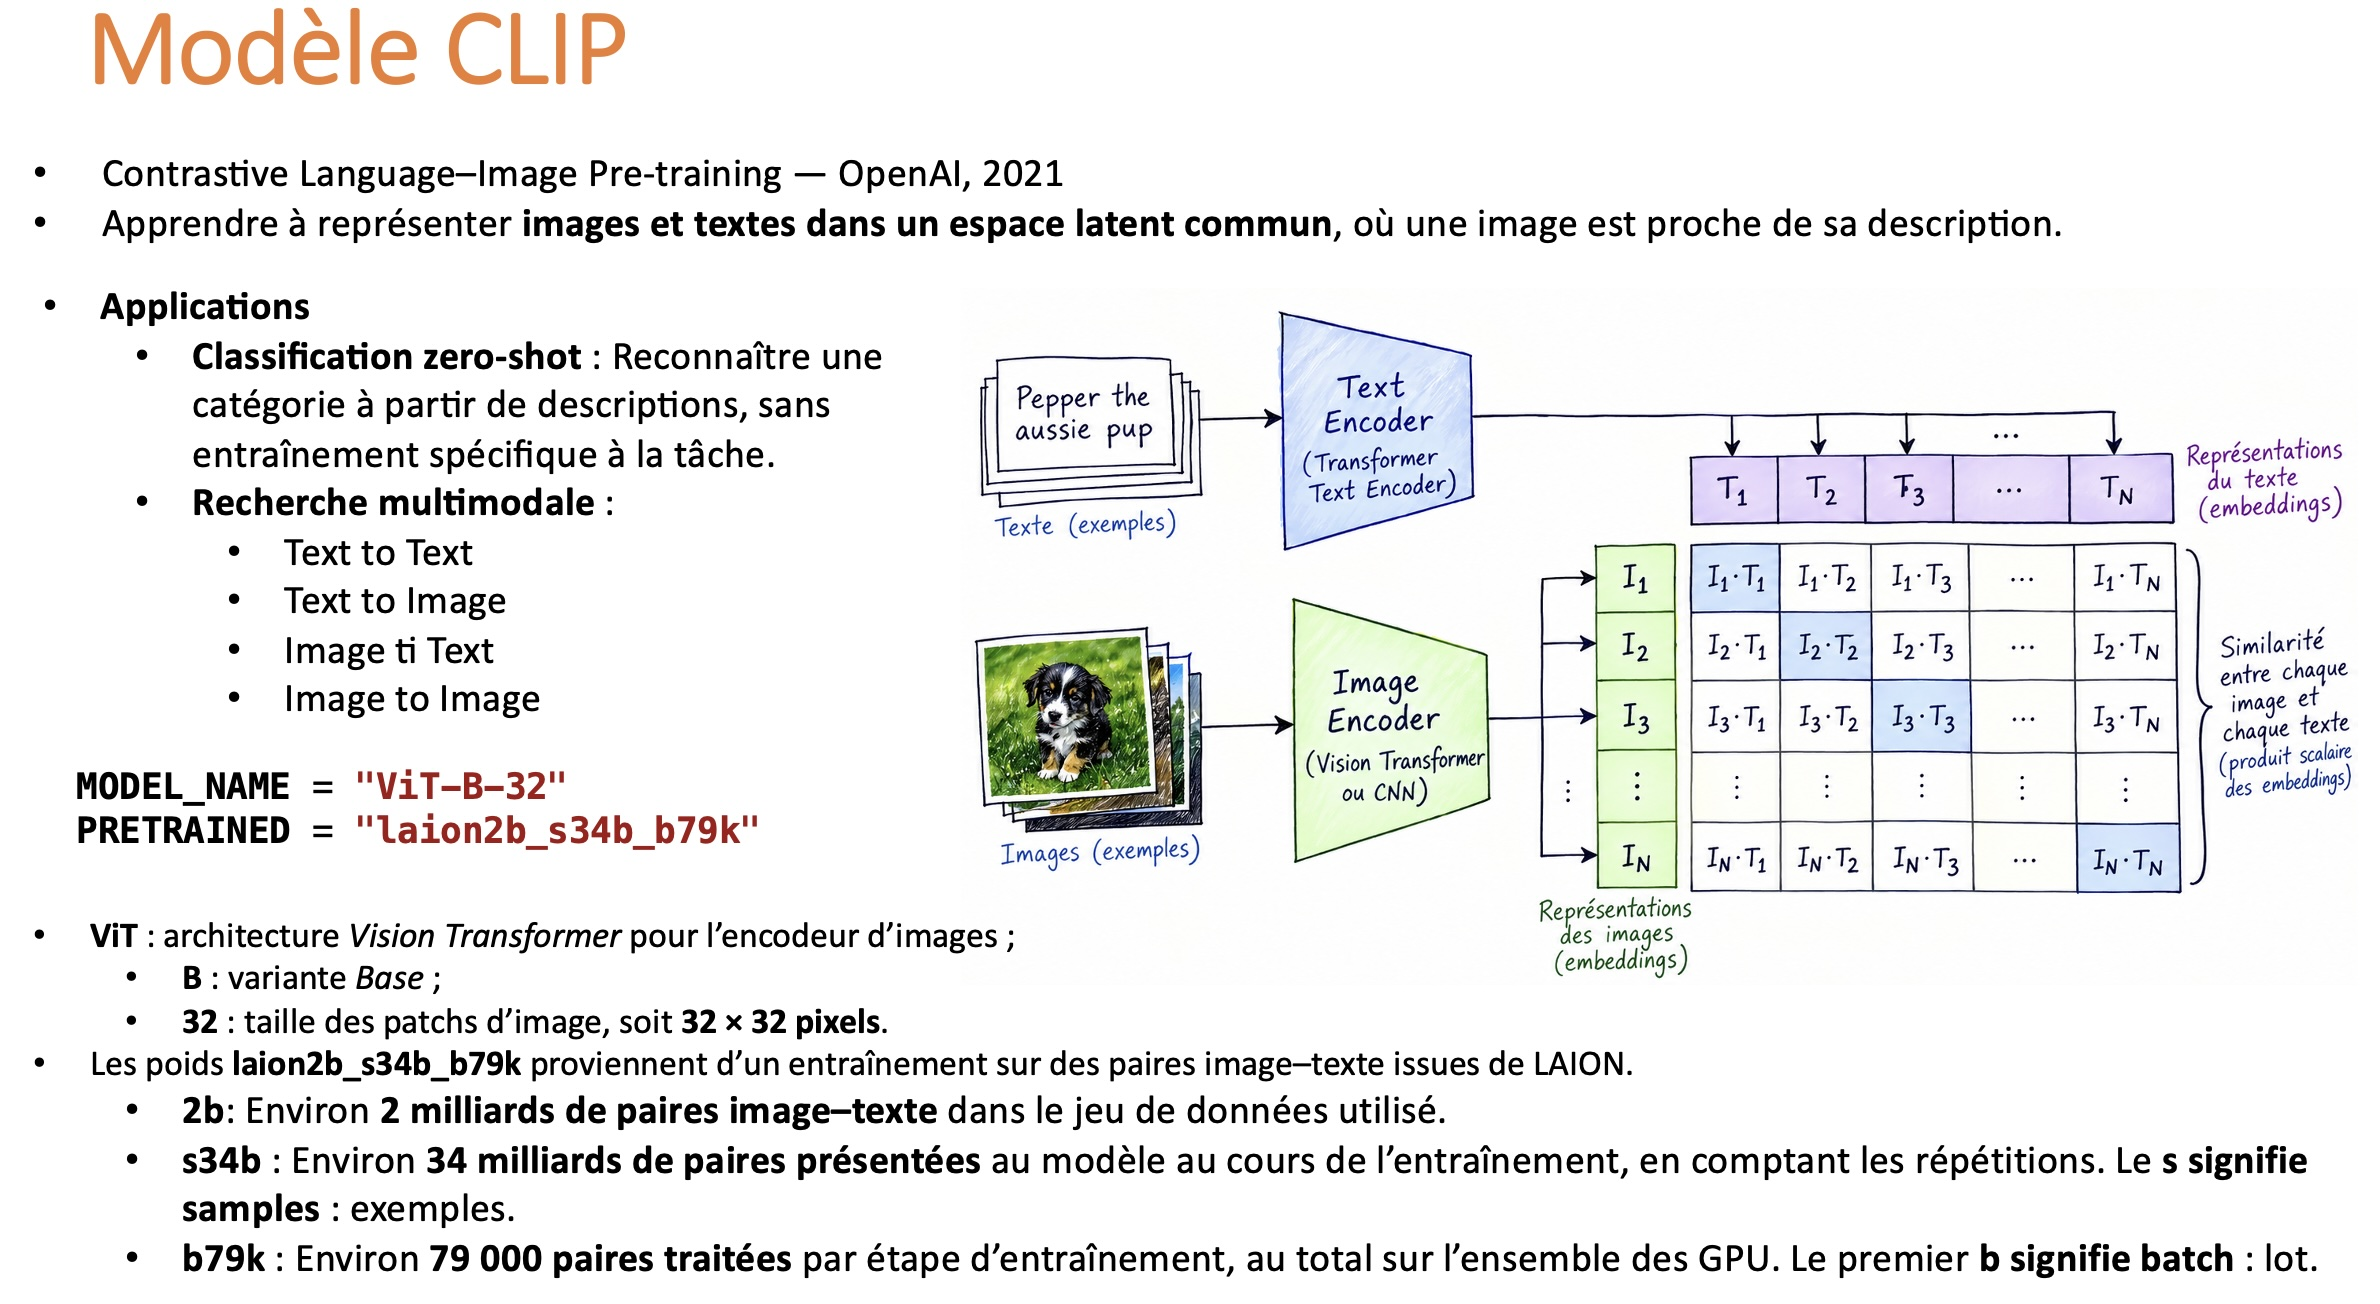

In [1]:
import torch
import open_clip
from PIL import Image

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

MODEL_NAME = "ViT-B-32"
PRETRAINED = "laion2b_s34b_b79k"

# Charger le modèle et le prétraitement des images
model, _, preprocess = open_clip.create_model_and_transforms(
    MODEL_NAME,
    pretrained=PRETRAINED
)
model = model.to(DEVICE).eval()

tokenizer = open_clip.get_tokenizer(MODEL_NAME)

# --- Préparer le texte ---
texte = "Un chat sur un canapé"
tokens = tokenizer([texte]).to(DEVICE)

# --- Préparer l'image ---
with Image.open("architecture_transformer.png") as image:
    tenseur_image = preprocess(image.convert("RGB"))

# Ajouter la dimension batch : [3, H, W] → [1, 3, H, W]
tenseur_image = tenseur_image.unsqueeze(0).to(DEVICE)

# --- Encoder le texte et l'image ---
with torch.inference_mode():
    vecteur_texte = model.encode_text(tokens)
    vecteur_image = model.encode_image(tenseur_image)

    # Normaliser les embeddings
    vecteur_texte = vecteur_texte / vecteur_texte.norm(dim=-1, keepdim=True)
    vecteur_image = vecteur_image / vecteur_image.norm(dim=-1, keepdim=True)

# Convertir en listes Python utilisables par ChromaDB
vecteur_texte = vecteur_texte[0].cpu().tolist()
vecteur_image = vecteur_image[0].cpu().tolist()

print("Dimension texte :", len(vecteur_texte))  # 512
print("Dimension image :", len(vecteur_image))  # 512

print("Embedding texte (5 premières valeurs) :", vecteur_texte[:5])
print("Embedding image (5 premières valeurs) :", vecteur_image[:5])

C:\Users\lenovo\Desktop\rag-multimodal-agentique\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\lenovo\Desktop\rag-multimodal-agentique\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\lenovo\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


C:\Users\lenovo\Desktop\rag-multimodal-agentique\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\lenovo\.cache\huggingface\hub\models--laion--CLIP-ViT-B-32-laion2B-s34B-b79K. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Dimension texte : 512
Dimension image : 512
Embedding texte (5 premières valeurs) : [0.023388348519802094, 0.0185304693877697, -0.0027199354954063892, 0.09746270626783371, -0.017327938228845596]
Embedding image (5 premières valeurs) : [0.051624078303575516, -0.13253627717494965, 0.005973437801003456, -0.06372925639152527, -0.0007503250380977988]


## Encoder un texte et une image avec CLIP

Ce code utilise **OpenCLIP** pour transformer un texte et une image en **embeddings** : des vecteurs numériques représentant leur contenu sémantique.

### 1. Importer les bibliothèques

- `torch` : exécute le modèle et manipule les tenseurs.
- `open_clip` : fournit le modèle CLIP et ses outils de préparation des données.
- `PIL.Image` : ouvre les fichiers image.

### 2. Choisir le périphérique

`DEVICE = "cuda" if torch.cuda.is_available() else "cpu"`

Le calcul utilise le GPU NVIDIA si CUDA est disponible, sinon le CPU.

### 3. Charger le modèle

- `MODEL_NAME = "ViT-B-32"` indique l’architecture du modèle.
- `PRETRAINED = "laion2b_s34b_b79k"` désigne les poids préentraînés à charger.

`open_clip.create_model_and_transforms(...)` retourne :
1. le modèle ;
2. le prétraitement destiné à l’entraînement, ignoré ici avec `_` ;
3. le prétraitement destiné à l’évaluation, conservé dans `preprocess`.

`model.to(DEVICE).eval()` déplace le modèle sur le périphérique choisi et active le mode évaluation.

### 4. Préparer le texte

`tokenizer = open_clip.get_tokenizer(MODEL_NAME)` récupère le tokenizer adapté au modèle.

`tokens = tokenizer([texte]).to(DEVICE)` :
- transforme le texte en identifiants numériques appelés **tokens** ;
- prépare une séquence de la longueur attendue par le modèle ;
- déplace le tenseur obtenu sur le même périphérique que le modèle.

Les crochets `[texte]` créent un lot contenant un seul texte.

> Les tokens ne sont pas encore des embeddings : ils constituent l’entrée de l’encodeur de texte.

### 5. Préparer l’image

`Image.open(...)` ouvre le fichier image. Le bloc `with` permet de fermer le fichier après son utilisation.

`image.convert("RGB")` garantit que l’image possède trois canaux de couleur : rouge, vert et bleu.

`preprocess(...)` prépare l’image pour le modèle, notamment par redimensionnement, recadrage, conversion en tenseur et normalisation des pixels.

`unsqueeze(0)` ajoute la dimension du lot :

**[canaux, hauteur, largeur] → [1, canaux, hauteur, largeur]**

Le tenseur est ensuite déplacé sur `DEVICE`.

### 6. Calculer les embeddings

Dans le bloc `torch.inference_mode()` :

- `model.encode_text(tokens)` produit l’embedding du texte ;
- `model.encode_image(tenseur_image)` produit l’embedding de l’image.

Ce mode désactive les mécanismes liés au calcul des gradients, inutiles ici, ce qui réduit le coût de l’inférence.

Avec ce modèle, chaque résultat a la forme **[1, 512]** : un lot d’un élément représenté par 512 valeurs.

### 7. Normaliser les embeddings

Chaque vecteur est divisé par sa norme :

`vecteur / vecteur.norm(dim=-1, keepdim=True)`

- `dim=-1` calcule la norme sur les composantes du vecteur.
- `keepdim=True` conserve une forme compatible avec la division.

Le vecteur obtenu a une norme de **1**. Pour deux vecteurs ainsi normalisés, leur produit scalaire correspond à leur similarité cosinus.

### 8. Convertir les résultats pour ChromaDB

`vecteur[0].cpu().tolist()` :
1. sélectionne le premier et unique embedding du lot ;
2. le transfère vers le CPU si nécessaire ;
3. le convertit en liste Python de nombres.

Ces listes peuvent être utilisées comme embeddings dans ChromaDB.

### 9. Afficher les résultats

- `len(vecteur)` affiche le nombre de dimensions : **512**.
- `vecteur[:5]` affiche seulement les cinq premières valeurs.

### À retenir

Le texte et l’image sont encodés par deux encodeurs différents, mais leurs embeddings se trouvent dans un **espace vectoriel commun**.

Cela permet de comparer leur contenu et, par exemple, de **rechercher des images à partir d’un texte**.

Ces embeddings ne permettent pas de reconstruire fidèlement le contenu original : il faut conserver le texte, l’image ou une référence vers celle-ci.

## Indiquer le fichier PDF

In [2]:
from pathlib import Path
import pymupdf

PDF_PATH = Path("./pdfs/attention is all you need.pdf")

OUTPUT_DIR = Path("resultats_pdf")
TEXT_DIR = OUTPUT_DIR / "textes"
IMAGE_DIR = OUTPUT_DIR / "images"

if not PDF_PATH.is_file():
    raise FileNotFoundError(f"Fichier introuvable : {PDF_PATH.resolve()}")

TEXT_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

print(f"PDF : {PDF_PATH.resolve()}")
print(f"Résultats : {OUTPUT_DIR.resolve()}")

PDF : C:\Users\lenovo\Desktop\rag-multimodal-agentique\pdfs\attention is all you need.pdf
Résultats : C:\Users\lenovo\Desktop\rag-multimodal-agentique\resultats_pdf


## Extraire le texte et les images

Le texte est enregistré dans un fichier par page ainsi que dans un fichier global. Les images sont enregistrées dans leur format extrait, par exemple PNG ou JPEG.

À savoir : cette extraction récupère les images intégrées au PDF, pas les dessins vectoriels. Une image présente sur plusieurs pages sera enregistrée pour chacune de ces pages. L’ordre de lecture du texte peut nécessiter des ajustements pour les mises en page complexes.

In [3]:
textes = []
nombre_images = 0
pages_sans_texte = []

with pymupdf.open(PDF_PATH) as document:
    nombre_pages = len(document)

    for numero_page, page in enumerate(document, start=1):
        # ---- Extraction du texte ----
        texte = page.get_text("text", sort=True)

        fichier_texte = TEXT_DIR / f"page_{numero_page:03d}.txt"
        fichier_texte.write_text(texte, encoding="utf-8")

        textes.append(f"===== PAGE {numero_page} =====\n\n{texte}")

        if not texte.strip():
            pages_sans_texte.append(numero_page)

        # ---- Extraction des images intégrées ----
        # Éviter d'extraire plusieurs fois la même image sur une page.
        images_vues = set()

        for image_info in page.get_images(full=True):
            xref = image_info[0]

            if xref in images_vues:
                continue

            images_vues.add(xref)

            try:
                image = document.extract_image(xref)

                if not image:
                    print(f"Image non extractible : page {numero_page}, xref {xref}")
                    continue

                extension = image["ext"]
                fichier_image = (
                    IMAGE_DIR
                    / f"page_{numero_page:03d}_image_{xref}.{extension}"
                )
                fichier_image.write_bytes(image["image"])

                nombre_images += 1

            except Exception as erreur:
                print(
                    f"Erreur d'extraction : page {numero_page}, "
                    f"image {xref} : {erreur}"
                )

# Enregistrer le texte de tout le document.
(OUTPUT_DIR / "texte_complet.txt").write_text(
    "\n\n".join(textes),
    encoding="utf-8"
)

print(f"Pages traitées : {nombre_pages}")
print(f"Images enregistrées : {nombre_images}")

if pages_sans_texte:
    print("Pages sans texte détectable :", pages_sans_texte)
    print("Si elles contiennent du texte scanné, utilisez l'OCR ci-dessous.")

Pages traitées : 11
Images enregistrées : 3


## Extraction du texte et des images d’un PDF pour un RAG multimodal
Ce code prépare les données d’un document PDF en séparant **le texte** et **les images intégrées**. Il correspond à une étape d’**ingestion** d’un pipeline RAG multimodal : il ne réalise pas encore la création d’embeddings, l’indexation ou la recherche.

### 1. Initialisation

Trois variables servent à suivre l’extraction :

- `textes` : conserve le texte de chaque page, précédé de son numéro.
- `nombre_images` : compte les images enregistrées.
- `pages_sans_texte` : mémorise les pages sans texte détectable.

Les chemins `PDF_PATH`, `TEXT_DIR`, `IMAGE_DIR` et `OUTPUT_DIR` doivent être définis au préalable, et les dossiers de sortie doivent exister.

### 2. Ouverture et parcours du PDF

`pymupdf.open(PDF_PATH)` ouvre le document. Le bloc `with` assure sa fermeture automatique à la fin du traitement.

- `len(document)` récupère le nombre total de pages.
- `enumerate(document, start=1)` parcourt les pages en les numérotant à partir de **1**.

### 3. Extraction et sauvegarde du texte

Pour chaque page, `page.get_text("text", sort=True)` extrait le texte brut. L’option `sort=True` cherche à restituer un ordre de lecture cohérent selon la disposition du texte, sans garantir un résultat parfait pour les mises en page complexes.

Le texte est ensuite :

1. Enregistré dans un fichier individuel, par exemple `page_001.txt`.
2. Ajouté à la liste `textes`, avec un repère comme `===== PAGE 1 =====`.

Le format `{numero_page:03d}` produit un numéro sur au moins trois chiffres : `001`, `002`, etc., ce qui facilite le tri des fichiers.

Enfin, `if not texte.strip()` détecte les pages dont le texte extrait est vide ou constitué uniquement d’espaces et de sauts de ligne. Leurs numéros sont ajoutés à `pages_sans_texte`.

> Une page sans texte extractible n’est pas nécessairement vide : elle peut contenir un scan, une illustration ou du texte représenté sous forme d’image.

### 4. Extraction des images intégrées

`page.get_images(full=True)` liste les images référencées par la page. Pour chacune, `image_info[0]` fournit son **xref**, un identifiant de référence interne au PDF.

L’ensemble `images_vues` évite d’extraire plusieurs fois la même référence d’image **sur une même page**. Il est réinitialisé à chaque page : une image réutilisée sur plusieurs pages peut donc être enregistrée plusieurs fois.

Pour chaque image non encore traitée :

1. `document.extract_image(xref)` récupère ses données.
2. `image["ext"]` fournit son extension, par exemple `png` ou `jpeg`.
3. `image["image"]` contient les données binaires, enregistrées avec `write_bytes()`.

Le nom du fichier indique la page et la référence de l’image, par exemple :  
`page_001_image_42.png`

Le compteur `nombre_images` augmente uniquement après un enregistrement réussi.

### 5. Gestion des erreurs

Le bloc `try / except` permet de poursuivre le traitement lorsqu’une image pose problème :

- Si l’extraction ne renvoie pas de données, un message signale une image non extractible.
- Si une exception survient pendant l’extraction ou l’enregistrement, un message précise la page, le xref et l’erreur rencontrée.

Cette protection concerne les images, pas l’ensemble des opérations du script.

### 6. Regroupement du texte et bilan

Après le parcours du PDF, `"\n\n".join(textes)` rassemble les textes des pages dans un fichier unique : **`texte_complet.txt`**, enregistré en UTF-8.

Le script affiche ensuite :

- Le nombre de pages traitées.
- Le nombre d’images enregistrées.
- Les numéros des pages sans texte détectable, s’il y en a.

Pour les pages contenant du texte scanné, il recommande une étape d’**OCR** (*reconnaissance optique de caractères*). Ce code ne réalise pas lui-même cette reconnaissance.

### Place dans un RAG multimodal

**PDF → Extraction texte/images → Préparation et embeddings → Indexation → Recherche → Génération**

Ce script réalise uniquement l’extraction. Les étapes suivantes pourront découper le texte en fragments, analyser les images, produire des embeddings adaptés et conserver les références aux pages pour citer les sources.

**Limite importante :** extraire les images intégrées n’équivaut pas à capturer toute l’apparence d’une page. Certains graphiques vectoriels, tableaux ou compositions visuelles peuvent nécessiter un rendu de la page en image ou un traitement spécialisé.

## Afficher un aperçu des résultats

APERÇU DU TEXTE

===== PAGE 1 =====

             Attention Is All You Need





     Ashish Vaswani∗      Noam Shazeer∗       Niki Parmar∗     Jakob Uszkoreit∗
      Google Brain          Google Brain       Google Research     Google Research
  avaswani@google.com   noam@google.com   nikip@google.com   usz@google.com

        Llion Jones∗          Aidan N. Gomez∗†            Łukasz Kaiser∗
     Google Research          University of Toronto              Google Brain
    llion@google.com     aidan@cs.toronto.edu     lukaszkaiser@google.com

                                               Illia Polosukhin∗‡
                         illia.polosukhin@gmail.com


                                Abstract

       The dominant sequence transduction models are based on complex recurrent or
        convolutional neural networks that include an encoder and a decoder. The best
        performing models also connect the encoder and decoder through an attention
       mechanism. We propose a new sim

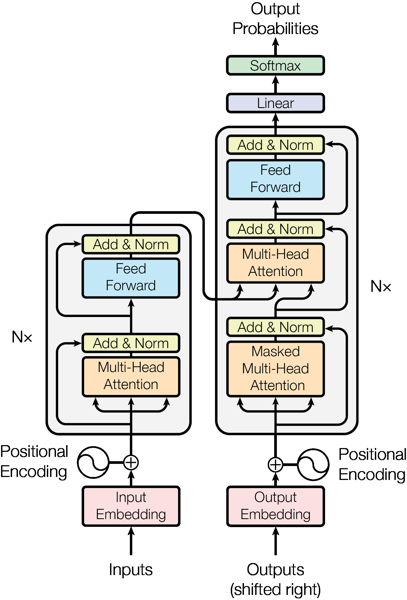

page_004_image_102.png


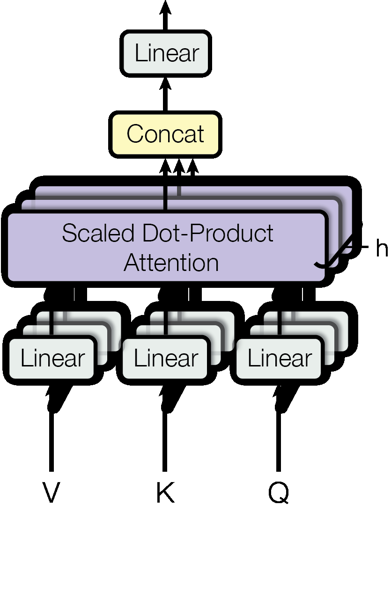

page_004_image_104.png


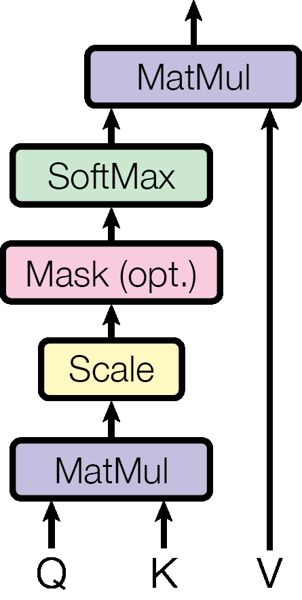

In [4]:
from PIL import Image
from IPython.display import display

texte_complet = (OUTPUT_DIR / "texte_complet.txt").read_text(
    encoding="utf-8"
)

print("APERÇU DU TEXTE\n")
print(texte_complet[:2000])

print("\nAPERÇU DES IMAGES\n")

for fichier in sorted(IMAGE_DIR.iterdir())[:5]:
    print(fichier.name)

    with Image.open(fichier) as image:
        apercu = image.copy()
        apercu.thumbnail((600, 600))
        display(apercu)

## Vérification du texte et des images extraits du PDF

Ce code affiche un **aperçu du texte et des images** enregistrés lors de l’étape précédente. Il permet de contrôler rapidement les données avant de poursuivre le pipeline RAG multimodal.

### 1. Importation des outils

- `Image`, de la bibliothèque **Pillow**, permet d’ouvrir et de redimensionner les images.
- `display`, fourni par **IPython**, permet de les afficher directement dans un notebook Jupyter.

### 2. Lecture du texte complet

`(OUTPUT_DIR / "texte_complet.txt").read_text(encoding="utf-8")` lit le fichier contenant le texte extrait de toutes les pages du PDF.

Son contenu est stocké dans la variable `texte_complet`.

> Le fichier doit avoir été créé lors de l’étape d’extraction, et `OUTPUT_DIR` doit pointer vers son dossier.

### 3. Affichage d’un aperçu du texte

Après le titre **APERÇU DU TEXTE**, l’instruction `print(texte_complet[:2000])` affiche les **2 000 premiers caractères** du document, ou tout son contenu s’il est plus court.

Cet aperçu permet notamment de vérifier :
- Que le texte a bien été extrait.
- Que les caractères accentués sont correctement lus.
- Que le début du document est exploitable.

**Attention :** le fichier entier est chargé en mémoire ; seule la quantité de texte affichée est limitée.

### 4. Sélection des fichiers à afficher

La boucle `for fichier in sorted(IMAGE_DIR.iterdir())[:5]:` :

1. Liste les éléments du dossier `IMAGE_DIR`.
2. Les trie par nom.
3. Sélectionne les **cinq premiers**, ou moins si le dossier en contient moins.

Le nom de chaque fichier est affiché avec `print(fichier.name)`. Les noms issus de l’extraction permettent de retrouver la page et la référence de l’image.

> Le code ne filtre pas les extensions : il suppose que les éléments sélectionnés sont des fichiers image compatibles avec Pillow.

### 5. Ouverture et redimensionnement des images

`with Image.open(fichier) as image:` ouvre chaque image et assure la fermeture du fichier à la sortie du bloc.

- `image.copy()` crée une copie en mémoire pour préparer l’aperçu.
- `apercu.thumbnail((600, 600))` réduit cette copie pour qu’elle tienne dans un cadre de **600 × 600 pixels**, tout en conservant ses proportions.
- `display(apercu)` affiche le résultat dans le notebook.

La méthode `thumbnail()` modifie la copie directement et n’agrandit pas les images déjà plus petites. **Aucun fichier image d’origine n’est modifié.**

### Place dans un RAG multimodal

**Extraction du PDF → Contrôle visuel → Préparation des données → Embeddings et indexation**

Cette cellule constitue un **contrôle rapide**, pas une validation complète : elle n’affiche que le début du texte et les cinq premiers fichiers. Elle ne réalise ni OCR, ni analyse automatique des images, ni création d’embeddings.

## Charger le modèle et ouvrir ChromaDB

Important : si vous changez de modèle ou de poids préentraînés, utilisez une nouvelle collection. Les embeddings de modèles différents ne sont pas interchangeables, même si leur dimension est identique.

In [5]:
from pathlib import Path
import hashlib
import re

import torch
import open_clip
import chromadb

from PIL import Image
from open_clip.tokenizer import SimpleTokenizer

# Dossiers produits par les cellules d'extraction
OUTPUT_DIR = Path("resultats_pdf")
TEXT_DIR = OUTPUT_DIR / "textes"
IMAGE_DIR = OUTPUT_DIR / "images"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

MODEL_NAME = "ViT-B-32"
PRETRAINED = "laion2b_s34b_b79k"

model, _, preprocess = open_clip.create_model_and_transforms(
    MODEL_NAME,
    pretrained=PRETRAINED
)

model = model.to(DEVICE).eval()
tokenizer = open_clip.get_tokenizer(MODEL_NAME)

# Tokeniseur BPE adapté au modèle CLIP choisi
bpe = SimpleTokenizer()

# Base persistante sur disque
client = chromadb.PersistentClient(path="chroma_pdf")

collection = client.get_or_create_collection(
    name="pdf_clip_vit_b32",
    embedding_function=None,  # Les embeddings sont calculés par notre code
    metadata={"hnsw:space": "cosine"}
)

print("Appareil :", DEVICE)
print("Éléments déjà présents :", collection.count())

Appareil : cpu
Éléments déjà présents : 0


## Initialisation du modèle CLIP et de la base vectorielle

Cette cellule prépare les outils nécessaires pour représenter les textes et les images extraits des PDF sous forme de **vecteurs numériques (embeddings)**, puis les stocker dans une base **ChromaDB**.

### 1. Importation des bibliothèques

- **`Path`** : construit et manipule les chemins des fichiers et des dossiers.
- **`hashlib`** : permet de calculer des empreintes numériques, utiles notamment pour créer des identifiants.
- **`re`** : fournit les expressions régulières pour rechercher, nettoyer ou découper du texte.
- **`torch`** : exécute les calculs du modèle sur CPU ou GPU.
- **`open_clip`** : charge le modèle CLIP et ses outils de préparation des données.
- **`chromadb`** : gère le stockage et la recherche des embeddings.
- **`Image`** : ouvre et manipule les images avec Pillow.
- **`SimpleTokenizer`** : fournit un tokeniseur BPE utilisé par CLIP.

Certains imports, comme `hashlib`, `re` et `Image`, ne sont pas encore utilisés dans cette cellule ; ils serviront aux étapes suivantes.

### 2. Définition des dossiers

Les chemins pointent vers les résultats des cellules d’extraction :

| Variable | Chemin | Contenu attendu |
|---|---|---|
| `OUTPUT_DIR` | `resultats_pdf` | Dossier principal des résultats |
| `TEXT_DIR` | `resultats_pdf/textes` | Textes extraits |
| `IMAGE_DIR` | `resultats_pdf/images` | Images extraites |

L’opérateur `/` de `Path` permet de construire les sous-chemins. Ces instructions définissent les chemins, mais **ne créent pas les dossiers**.

### 3. Choix de l’appareil de calcul

`DEVICE` prend la valeur :

- **`"cuda"`** si un GPU compatible CUDA est accessible à PyTorch ;
- **`"cpu"`** sinon.

Le GPU peut accélérer le calcul des embeddings.

### 4. Chargement du modèle préentraîné

Le modèle choisi est **`ViT-B-32`** :

- **ViT** : architecture *Vision Transformer* pour l’encodeur d’images ;
- **B** : variante *Base* ;
- **32** : taille des patchs d’image, soit **32 × 32 pixels**.

Les poids **`laion2b_s34b_b79k`** proviennent d’un entraînement sur des paires image–texte issues de LAION.
- **2b**: Environ 2 milliards de paires image–texte dans le jeu de données utilisé.
- **s34b** : Environ 34 milliards de paires présentées au modèle au cours de l’entraînement, en comptant les répétitions. Le s signifie samples : exemples.
- **b79k**	Environ 79 000 paires traitées par étape d’entraînement, au total sur l’ensemble des GPU. Le premier b signifie batch : lot.

La fonction `create_model_and_transforms` renvoie :
1. **`model`** : le modèle CLIP préentraîné ;
2. les transformations d’entraînement, ignorées ici avec **`_`** ;
3. **`preprocess`** : les transformations pour préparer les images à l’inférence, notamment le redimensionnement, le recadrage, la conversion en tenseur et la normalisation.

CLIP peut encoder les images et les textes dans un **espace vectoriel commun**, ce qui permet de comparer leur contenu sémantique.

### 5. Préparation du modèle pour l’inférence

L’instruction `model.to(DEVICE).eval()` :

- déplace le modèle vers le GPU ou le CPU sélectionné ;
- active le **mode évaluation**, adapté à l’utilisation d’un modèle déjà entraîné.

> `eval()` ne désactive pas le calcul des gradients. Lors de l’encodage, on utilisera généralement `torch.no_grad()` ou `torch.inference_mode()` pour réduire la consommation mémoire.

### 6. Initialisation des tokeniseurs

- **`tokenizer`**, obtenu avec `open_clip.get_tokenizer(MODEL_NAME)`, prépare les textes au format attendu par le modèle : identifiants de tokens, tokens spéciaux et longueur adaptée.
- **`bpe`**, créé avec `SimpleTokenizer()`, permet une manipulation plus directe de la tokenisation **BPE** (*Byte Pair Encoding*), par exemple pour compter les tokens ou préparer un découpage du texte.

La tokenisation transforme le texte en unités numériques ; **elle ne calcule pas encore son embedding**.

### 7. Ouverture de la base persistante ChromaDB

`chromadb.PersistentClient(path="chroma_pdf")` ouvre ou crée une base enregistrée dans le dossier local **`chroma_pdf`**.

La persistance permet de retrouver les données lors d’une exécution ultérieure, à condition de réutiliser le même chemin.

### 8. Création ou récupération de la collection

La collection **`pdf_clip_vit_b32`** regroupe les éléments à indexer.

- **`get_or_create_collection`** : récupère la collection si elle existe, sinon la crée.
- **`embedding_function=None`** : ChromaDB ne calculera pas automatiquement les embeddings ; notre code devra les fournir.
- **`"hnsw:space": "cosine"`** : configure, lors de la création, la distance cosinus pour la recherche vectorielle avec l’index HNSW.

La distance cosinus compare l’orientation des vecteurs : **plus elle est faible, plus les représentations sont proches**.

> Si la collection existe déjà, cet appel ne reconfigure pas automatiquement sa métrique. Les embeddings ajoutés doivent aussi rester compatibles avec ceux déjà présents : même modèle et même dimension.

### 9. Affichage de contrôle

Les deux dernières instructions affichent :

- l’appareil utilisé : **CPU ou CUDA** ;
- le nombre d’éléments déjà enregistrés dans la collection.

### Résumé

Cette cellule **initialise l’environnement de recherche multimodale** : chemins, modèle CLIP, préparation des images, tokeniseurs et base vectorielle persistante.

**Elle ne lit pas encore les fichiers extraits, ne calcule aucun embedding et n’ajoute aucun élément à la collection.**

## Préparer le découpage et les embeddings

In [6]:
def decouper_texte(texte, taille=60, chevauchement=10):
    """Découper le texte en fragments courts adaptés à CLIP."""
    if not 0 <= chevauchement < taille:
        raise ValueError("Le chevauchement doit être inférieur à la taille.")

    tokens = bpe.encode(texte)

    for debut in range(0, len(tokens), taille - chevauchement):
        fragment = bpe.decode(tokens[debut:debut + taille]).strip()

        if fragment:
            yield fragment

        if debut + taille >= len(tokens):
            break

## Découpage du texte en fragments adaptés à CLIP

La fonction `decouper_texte` divise un texte en **fragments courts**, avec un **chevauchement** entre deux fragments successifs. Ce découpage permet de traiter des textes longs avec le modèle CLIP, dont la longueur d’entrée est limitée.

### 1. Paramètres de la fonction

| Paramètre | Valeur par défaut | Rôle |
|---|---|---|
| `texte` | — | Texte à découper |
| `taille` | `60` | Nombre maximal de tokens BPE par fragment |
| `chevauchement` | `10` | Nombre de tokens partagés entre deux fragments successifs |

Un **token** n’est pas nécessairement un mot : il peut représenter un mot entier, une partie de mot ou un signe de ponctuation.

### 2. Vérification des paramètres

La condition `0 <= chevauchement < taille` garantit que :

- le chevauchement est positif ou nul ;
- il est strictement inférieur à la taille du fragment ;
- le déplacement entre deux fragments reste strictement positif.

Si cette condition n’est pas respectée, la fonction lève une **`ValueError`**.

Les paramètres `taille` et `chevauchement` sont supposés être des entiers.

### 3. Tokenisation du texte

L’instruction `tokens = bpe.encode(texte)` transforme le texte en une liste d’identifiants de tokens, à l’aide du tokeniseur `bpe` initialisé précédemment.

Le découpage se fait donc **en tokens**, et non en caractères ou en mots.

### 4. Découpage avec chevauchement

La boucle avance avec un pas égal à :

**pas = taille − chevauchement**

Avec les valeurs par défaut :

**pas = 60 − 10 = 50 tokens**

Les fragments couvrent ainsi les positions suivantes, avec une borne de fin exclue :

| Fragment | Début | Fin maximale |
|---|---:|---:|
| 1 | 0 | 60 |
| 2 | 50 | 110 |
| 3 | 100 | 160 |

Deux fragments successifs partagent donc **10 tokens**.

Ce chevauchement conserve une partie du contexte aux frontières des fragments, ce qui peut améliorer la recherche d’informations réparties sur deux passages.

### 5. Reconstruction des fragments

Pour chaque position de départ :

- `tokens[debut:debut + taille]` sélectionne au maximum `taille` tokens ;
- `bpe.decode(...)` reconstruit un texte à partir de ces tokens ;
- `.strip()` retire les espaces et autres caractères blancs au début et à la fin.

Le dernier fragment peut contenir moins de tokens que les précédents.

> Le découpage suit les positions des tokens : il ne respecte pas nécessairement les limites des phrases ou des mots. Le texte reconstruit n’est pas non plus garanti identique à la mise en forme d’origine.

### 6. Production progressive avec `yield`

Si le fragment n’est pas vide, `yield fragment` le fournit au code appelant.

La fonction est donc un **générateur** : elle produit les fragments un par un, au lieu de construire immédiatement une liste complète.

Cela évite de stocker tous les fragments simultanément, même si la liste complète des tokens reste en mémoire.

Pour obtenir une liste, on peut utiliser :

`fragments = list(decouper_texte(texte))`

Si le texte ne produit aucun token, aucun fragment n’est renvoyé.

### 7. Arrêt à la fin du texte

La condition `debut + taille >= len(tokens)` arrête la boucle dès que le fragment courant atteint la fin du texte.

Elle évite de produire ensuite un fragment supplémentaire contenant seulement une partie de la fin déjà couverte.

### 8. Pourquoi choisir 60 tokens pour CLIP ?

Le modèle CLIP utilisé ici possède généralement une fenêtre de **77 tokens**, incluant les tokens spéciaux.

Une taille de **60 tokens BPE** laisse une marge sous cette limite. Les fragments devront néanmoins être préparés avec le `tokenizer` du modèle avant leur encodage.

> La longueur finale dépend de cette tokenisation : découper puis décoder les tokens ne remplace pas la préparation des entrées attendue par CLIP.

### Résumé

Cette fonction transforme un texte long en **fragments courts et partiellement superposés**, destinés à être encodés individuellement par CLIP.

**Elle prépare les textes, mais ne calcule pas leurs embeddings et ne les enregistre pas dans ChromaDB.**

### Une autre solution en utilisant RecursiveCharacterTextSplitter de langchain

In [7]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

def decouper_texte_V2(texte, taille=60, chevauchement=10):
    """Découper le texte en privilégiant les limites naturelles."""
    if not 0 <= chevauchement < taille:
        raise ValueError("Le chevauchement doit être inférieur à la taille.")

    splitter = RecursiveCharacterTextSplitter(
        chunk_size=taille,
        chunk_overlap=chevauchement,
        length_function=lambda texte: len(bpe.encode(texte)),
        separators=["\n\n", "\n", " ", ""],
        strip_whitespace=True,
    )

    yield from splitter.split_text(texte)

## Découpage du texte en privilégiant les limites naturelles

La fonction `decouper_texte_V2` découpe un texte en **fragments courts**, en essayant de préserver les paragraphes, les lignes et les mots.

Contrairement à la première version, qui découpait directement une liste de tokens, cette version utilise **`RecursiveCharacterTextSplitter`** de LangChain pour choisir des points de coupure plus naturels.

### 1. Importation de l’outil de découpage

`RecursiveCharacterTextSplitter` découpe progressivement le texte à l’aide d’une liste de séparateurs.

Si une portion est trop longue, il utilise un séparateur plus fin pour continuer à la diviser.

### 2. Paramètres de la fonction

| Paramètre | Valeur par défaut | Rôle |
|---|---|---|
| `texte` | — | Texte à découper |
| `taille` | `60` | Taille cible maximale d’un fragment, mesurée en tokens BPE |
| `chevauchement` | `10` | Chevauchement cible entre les fragments, mesuré en tokens BPE |

Un **token** peut représenter un mot, une partie de mot ou un signe de ponctuation.

### 3. Vérification des paramètres

La condition `0 <= chevauchement < taille` vérifie que :

- le chevauchement est positif ou nul ;
- il est strictement inférieur à la taille des fragments.

Sinon, une **`ValueError`** est levée.

Les paramètres `taille` et `chevauchement` sont supposés être des entiers.

### 4. Mesure de la longueur en tokens

L’option :

`length_function=lambda texte: len(bpe.encode(texte))`

définit la méthode utilisée pour mesurer la longueur du texte :

1. `bpe.encode(texte)` transforme le texte en tokens ;
2. `len(...)` compte ces tokens.

Ainsi, malgré le nom *CharacterTextSplitter*, la taille des fragments est évaluée ici **en tokens BPE, et non en caractères**.

Le tokeniseur `bpe` doit avoir été initialisé dans une cellule précédente.

### 5. Ordre des séparateurs

La liste `["\n\n", "\n", " ", ""]` définit les séparateurs, du plus général au plus fin :

| Séparateur | Découpage privilégié |
|---|---|
| `"\n\n"` | Entre les paragraphes |
| `"\n"` | Entre les lignes |
| `" "` | Entre les mots |
| `""` | Entre les caractères, en dernier recours |

Le découpage est dit **récursif** : lorsqu’une portion dépasse la taille souhaitée, l’outil essaie de la diviser avec les séparateurs suivants.

Il regroupe ensuite les petites portions pour constituer les fragments.

> Cette configuration privilégie les paragraphes, les lignes et les mots, mais ne reconnaît pas explicitement les limites des phrases.

### 6. Taille et chevauchement des fragments

- **`chunk_size=taille`** définit la limite de taille utilisée par l’algorithme.
- **`chunk_overlap=chevauchement`** définit la quantité de contexte qu’il essaie de conserver entre deux fragments.

Avec les valeurs par défaut, l’objectif est de produire des fragments d’environ **60 tokens maximum**, avec jusqu’à **10 tokens de contexte partagé**.

Contrairement à un découpage par fenêtres fixes, le chevauchement réel n’est pas nécessairement de 10 tokens : il dépend des portions disponibles et des séparateurs rencontrés. Il peut être plus faible, voire nul.

> Le comptage BPE n’est pas strictement additif : le nombre de tokens d’un texte assemblé peut différer de la somme des nombres de tokens de ses parties. Si une limite stricte est nécessaire, il faut vérifier la longueur des fragments finaux avec le tokeniseur du modèle.

### 7. Nettoyage des extrémités

L’option `strip_whitespace=True` retire les caractères blancs au début et à la fin des fragments, notamment les espaces et les retours à la ligne.

Elle ne supprime pas systématiquement les espaces ou les sauts de ligne à l’intérieur du texte.

### 8. Production des fragments

L’instruction :

`yield from splitter.split_text(texte)`

transmet successivement chaque fragment renvoyé par `split_text`.

La fonction peut donc être parcourue dans une boucle ou convertie en liste :

`fragments = list(decouper_texte_V2(texte))`

**Attention :** même si la fonction utilise un générateur, `split_text(texte)` construit d’abord une liste complète des fragments. Le découpage n’est donc pas entièrement réalisé à la demande.

### 9. Comparaison avec la première version

| Aspect | Première version | Version V2 |
|---|---|---|
| Principe | Fenêtres sur une liste de tokens | Découpage récursif selon des séparateurs |
| Points de coupure | Positions fixes de tokens | Limites naturelles privilégiées |
| Chevauchement | Fixe dans la séquence de tokens | Variable selon le découpage |
| Texte produit | Reconstruit par décodage BPE | Issu des portions du texte d’origine |
| Production | Fragments décodés un par un | Liste calculée, puis parcourue |

### Résumé

Cette version cherche à produire des fragments **plus lisibles et mieux structurés**, tout en mesurant leur taille avec le tokeniseur BPE de CLIP.

**Elle prépare le texte pour l’encodage, mais ne calcule aucun embedding et n’enregistre aucune donnée dans ChromaDB.**

## Encodage des textes en vecteurs avec CLIP

In [8]:
@torch.inference_mode()
def encoder_textes(textes):
    tokens = tokenizer(textes).to(DEVICE)
    vecteurs = model.encode_text(tokens).float()

    vecteurs = vecteurs / vecteurs.norm(
        dim=-1, keepdim=True
    ).clamp_min(1e-12)

    return vecteurs.cpu().tolist()

La fonction `encoder_textes` transforme un lot de textes en **embeddings**, c’est-à-dire des vecteurs numériques représentant leur contenu.

Ces vecteurs peuvent ensuite être stockés dans ChromaDB et comparés à ceux d’autres textes ou d’images encodées avec le même modèle CLIP.

### 1. Désactivation du calcul des gradients

Le décorateur `@torch.inference_mode()` exécute la fonction en **mode inférence** :

- aucun gradient n’est calculé ;
- la consommation mémoire est réduite ;
- certains traitements internes nécessaires à l’entraînement sont désactivés.

Ce mode convient à l’utilisation d’un modèle préentraîné pour produire des embeddings.

> `inference_mode()` ne remplace pas `model.eval()`. Le modèle a déjà été placé en mode évaluation dans la cellule d’initialisation.

### 2. Préparation des textes

L’instruction `tokens = tokenizer(textes).to(DEVICE)` réalise deux opérations :

1. **Tokenisation** : conversion des textes en identifiants numériques, avec les tokens spéciaux et la mise à longueur attendus par CLIP.
2. **Transfert** : déplacement du tenseur sur l’appareil de calcul sélectionné, CPU ou GPU.

Pour un lot de `N` textes, le tenseur obtenu possède généralement la forme **`[N, 77]`** avec le modèle utilisé ici.

> Les textes doivent respecter la longueur d’entrée du modèle. Selon le tokeniseur et sa configuration, les textes trop longs peuvent être tronqués : le découpage préalable permet de limiter les pertes d’information.

### 3. Calcul des embeddings

L’instruction `vecteurs = model.encode_text(tokens).float()` :

- utilise l’encodeur de texte de CLIP pour produire un vecteur par texte ;
- convertit les résultats en **nombres flottants sur 32 bits** avec `.float()`.

Pour le modèle **`ViT-B-32`** chargé précédemment, chaque embedding comporte **512 composantes**.

Un lot de `N` textes produit donc un tenseur de forme **`[N, 512]`**.

Ces vecteurs se trouvent dans le même espace de représentation que les embeddings d’images produits par le modèle CLIP correspondant.

### 4. Normalisation des vecteurs

L’opération `vecteurs / vecteurs.norm(dim=-1, keepdim=True).clamp_min(1e-12)` applique une **normalisation L2** à chaque vecteur.

Pour un vecteur \(v\), cette opération s’écrit :
$$
\hat{v} = \frac{v}{\max(\|v\|_2,\;10^{-12})}
$$
Les paramètres ont les rôles suivants :

| Élément | Rôle |
|---|---|
| `dim=-1` | Calcule la norme sur les composantes de chaque vecteur |
| `keepdim=True` | Conserve une dimension de taille 1 pour permettre la division de chaque ligne par sa norme |
| `clamp_min(1e-12)` | Fixe un minimum au dénominateur pour éviter une division par zéro |

Pour les vecteurs non nuls de norme suffisamment grande, la norme devient **égale à 1**, à la précision numérique près.

Cette normalisation facilite les comparaisons : pour deux vecteurs unitaires, leur **produit scalaire correspond à leur similarité cosinus**.

> Un vecteur nul reste nul après cette opération.

### 5. Conversion pour le stockage

L’instruction `return vecteurs.cpu().tolist()` :

1. transfère les vecteurs vers le **CPU**, s’ils étaient sur GPU ;
2. convertit le tenseur en une **liste Python de listes de nombres**.

Chaque sous-liste représente l’embedding d’un texte, dans le même ordre que les textes fournis en entrée.

Ce format peut être transmis à ChromaDB via son paramètre `embeddings`.

### 6. Exemple d’utilisation

Pour l’appel :

`embeddings = encoder_textes(["Un chat sur un canapé.", "Une plage au coucher du soleil."])`

le résultat contient :

- **2 embeddings**, un par texte ;
- **512 valeurs par embedding** avec le modèle utilisé.

Tous les textes sont encodés en un seul lot. Pour un grand nombre de fragments, il est préférable d’appeler la fonction sur plusieurs petits lots afin de maîtriser la consommation mémoire.

### Résumé

Cette fonction réalise la chaîne suivante :

**Textes → tokenisation → encodage CLIP → normalisation L2 → listes Python**

Elle utilise les objets `tokenizer`, `model` et `DEVICE` initialisés précédemment.

**Elle calcule les embeddings, mais ne les enregistre pas elle-même dans ChromaDB.**

## Encodage d’une image en vecteur avec CLIP

In [9]:
@torch.inference_mode()
def encoder_image(chemin):
    with Image.open(chemin) as image:
        tenseur = preprocess(image.convert("RGB"))

    tenseur = tenseur.unsqueeze(0).to(DEVICE)
    vecteur = model.encode_image(tenseur).float()

    vecteur = vecteur / vecteur.norm(
        dim=-1, keepdim=True
    ).clamp_min(1e-12)

    return vecteur.cpu().tolist()[0]

La fonction `encoder_image` transforme une image en un **embedding**, c’est-à-dire un vecteur numérique représentant son contenu visuel.

Ce vecteur peut ensuite être comparé aux embeddings de textes ou d’autres images produits par le même modèle CLIP.

### 1. Exécution en mode inférence

Le décorateur `@torch.inference_mode()` désactive le calcul des gradients et certains traitements liés à l’entraînement.

Il permet de réduire la consommation mémoire lors du calcul de l’embedding.

> Ce décorateur ne remplace pas `model.eval()`, appelé précédemment pour placer le modèle en mode évaluation.

### 2. Ouverture de l’image

L’instruction `with Image.open(chemin) as image` ouvre l’image située au chemin fourni.

Le gestionnaire de contexte `with` garantit la fermeture du fichier à la sortie du bloc, même en cas d’erreur.

Le paramètre `chemin` peut notamment être une chaîne de caractères ou un objet `Path`.

### 3. Conversion et préparation de l’image

L’instruction `preprocess(image.convert("RGB"))` réalise deux opérations :

- **Conversion en RGB** : représente l’image avec trois canaux de couleur, rouge, vert et bleu.
- **Prétraitement** : applique les transformations attendues par le modèle CLIP.

Pour la configuration utilisée, ces transformations comprennent généralement :

1. le redimensionnement ;
2. le recadrage central ;
3. la conversion en tenseur ;
4. la normalisation des valeurs des pixels.

Le tenseur obtenu possède généralement la forme **`[3, 224, 224]`** :

| Dimension | Signification |
|---|---|
| `3` | Nombre de canaux de couleur |
| `224` | Hauteur de l’image préparée |
| `224` | Largeur de l’image préparée |

> Le recadrage peut retirer une partie des bords de l’image. La conversion en RGB supprime également un éventuel canal de transparence.

### 4. Ajout de la dimension de lot

L’instruction `tenseur.unsqueeze(0).to(DEVICE)` :

- ajoute une dimension au début du tenseur avec `unsqueeze(0)` ;
- déplace le tenseur vers le CPU ou le GPU sélectionné.

La forme passe ainsi de **`[3, 224, 224]`** à **`[1, 3, 224, 224]`**.

Le premier nombre, **1**, indique que le lot contient une seule image. Cette dimension est nécessaire, car le modèle attend des images organisées en lots.

### 5. Calcul de l’embedding

L’instruction `model.encode_image(tenseur).float()` :

- calcule la représentation vectorielle de l’image avec l’encodeur visuel de CLIP ;
- convertit le résultat en nombres flottants sur **32 bits**.

Avec le modèle **`ViT-B-32`** chargé précédemment, le résultat possède la forme **`[1, 512]`** : un embedding de 512 composantes pour une image.

Ce vecteur est une représentation du contenu visuel, et non une description textuelle de l’image.

### 6. Normalisation du vecteur

L’opération de normalisation divise le vecteur par sa norme L2 :

\[
\hat{v} = \frac{v}{\max(\|v\|_2,\;10^{-12})}
\]

| Élément | Rôle |
|---|---|
| `dim=-1` | Calcule la norme sur les 512 composantes du vecteur |
| `keepdim=True` | Conserve une forme compatible avec la division |
| `clamp_min(1e-12)` | Empêche une division par zéro en imposant un minimum au dénominateur |

Pour un vecteur non nul de norme suffisamment grande, cette opération produit un vecteur de **norme égale à 1**, à la précision numérique près.

La normalisation facilite les comparaisons : le produit scalaire de deux vecteurs unitaires correspond à leur **similarité cosinus**.

### 7. Conversion en liste Python

L’instruction `return vecteur.cpu().tolist()[0]` :

1. transfère le résultat vers le **CPU** ;
2. convertit le tenseur en liste Python ;
3. sélectionne le premier et unique embedding avec `[0]`.

La fonction renvoie donc une **liste simple de 512 nombres**, et non une liste contenant une liste.

> Contrairement à `encoder_textes`, qui traite un lot et renvoie plusieurs vecteurs, `encoder_image` traite une seule image et renvoie directement son vecteur.

### 8. Exemple d’utilisation

`embedding = encoder_image(IMAGE_DIR / "image_001.png")`

La variable `embedding` contient alors le vecteur normalisé représentant l’image.

Pour ajouter cette seule image dans ChromaDB, il faudra fournir une liste d’embeddings, par exemple avec le paramètre `embeddings=[embedding]`.

### Résumé

Cette fonction réalise la chaîne suivante :

**Fichier image → conversion RGB → prétraitement → encodage CLIP → normalisation L2 → liste Python**

Elle utilise les objets `Image`, `preprocess`, `model` et `DEVICE` initialisés précédemment.

**Elle calcule l’embedding de l’image, mais ne l’enregistre pas elle-même dans ChromaDB.**

## Extraction du numéro de page depuis un nom de fichier

In [10]:
def numero_page(chemin):
    correspondance = re.search(r"page_(\d+)", Path(chemin).stem)
    return int(correspondance.group(1)) if correspondance else -1

La fonction `numero_page` recherche un numéro de page dans le nom d’un fichier, puis le renvoie sous forme d’entier.

Elle attend un nom contenant le motif **`page_` suivi de chiffres**, comme `document_page_12.png`.

### 1. Récupération du nom sans extension

L’expression `Path(chemin).stem` récupère le nom du fichier sans son extension finale et sans ses dossiers parents.

Par exemple :

`resultats_pdf/images/document_page_12.png` → `document_page_12`

La recherche porte donc uniquement sur le **nom du fichier**, et non sur le chemin complet.

### 2. Recherche du numéro avec une expression régulière

L’appel `re.search(r"page_(\d+)", Path(chemin).stem)` recherche la première occurrence du motif suivant :

| Élément | Signification |
|---|---|
| `r"..."` | Chaîne brute Python, adaptée à l’écriture d’expressions régulières |
| `page_` | Texte littéral à rechercher |
| `\d+` | Un ou plusieurs chiffres |
| `(...)` | Groupe de capture permettant de récupérer les chiffres trouvés |

La variable `correspondance` contient :

- un objet de correspondance si le motif est trouvé ;
- `None` dans le cas contraire.

> La recherche est sensible à la casse : `page_12` est reconnu, mais pas `Page_12`.

### 3. Conversion et valeur de retour

L’instruction `int(correspondance.group(1)) if correspondance else -1` :

- récupère les chiffres du premier groupe avec `group(1)` ;
- les convertit en entier avec `int(...)` ;
- renvoie **`-1`** si aucun numéro n’est trouvé.

Les éventuels zéros au début disparaissent lors de la conversion : `page_003` donne **3**.

### 4. Exemples

| Chemin fourni | Résultat |
|---|---:|
| `resultats_pdf/textes/page_1.txt` | `1` |
| `resultats_pdf/images/document_page_12.png` | `12` |
| `page_003_image_2.jpg` | `3` |
| `image.png` | `-1` |
| `Page_5.png` | `-1` |

Si plusieurs motifs sont présents, par exemple dans `page_2_page_8.png`, seule la **première occurrence** est utilisée : la fonction renvoie **2**.

### Résumé

Cette fonction permet de récupérer le numéro de page associé à un fichier extrait d’un PDF, notamment pour l’enregistrer dans les **métadonnées de ChromaDB**.

Elle utilise `Path` et `re`, importés précédemment.

**Elle analyse uniquement le nom du fichier : elle ne lit pas son contenu, ne vérifie pas son existence et ne contrôle pas que le numéro correspond à une page réelle du PDF.**

## Indexation des textes du PDF dans ChromaDB

Chaque fragment possède :

- son embedding ;
- son texte ;
- le numéro de page ;
- l’identifiant du PDF ;
- le chemin du fichier source.

In [11]:
# PDF_PATH provient des cellules précédentes
PDF_PATH = Path(PDF_PATH)

# Identifiant lié au contenu du PDF
document_id = hashlib.sha256(PDF_PATH.read_bytes()).hexdigest()[:24]

# Supprimer l'ancienne version de l'index de ce PDF.
# Cela évite les fragments obsolètes après une nouvelle extraction.
collection.delete(where={"document_id": document_id})

ids = []
documents = []
metadatas = []

for fichier in sorted(TEXT_DIR.glob("page_*.txt")):
    texte = fichier.read_text(encoding="utf-8")
    page = numero_page(fichier)

    for index, fragment in enumerate(decouper_texte(texte)):
        ids.append(f"{document_id}:texte:{page}:{index}")
        documents.append(fragment)

        metadatas.append({
            "type": "texte",
            "document_id": document_id,
            "pdf": PDF_PATH.name,
            "page": page,
            "fragment": index,
            "source": str(fichier.resolve())
        })

# Indexation par lots
TAILLE_LOT = 64

for debut in range(0, len(documents), TAILLE_LOT):
    fin = debut + TAILLE_LOT
    lot = documents[debut:fin]

    collection.upsert(
        ids=ids[debut:fin],
        documents=lot,
        metadatas=metadatas[debut:fin],
        embeddings=encoder_textes(lot)
    )

print(f"{len(documents)} fragments de texte indexés.")

171 fragments de texte indexés.


Cette cellule récupère les textes extraits du PDF, les découpe en fragments, calcule leurs **embeddings avec CLIP**, puis les enregistre dans la collection ChromaDB.

Chaque fragment est accompagné de métadonnées permettant de retrouver son document, sa page et son fichier source.

### 1. Préparation du chemin du PDF

L’instruction `PDF_PATH = Path(PDF_PATH)` convertit le chemin défini précédemment en objet `Path`.

Cela facilite l’accès :
- au contenu du fichier ;
- à son nom ;
- aux informations liées à son chemin.

### 2. Création d’un identifiant lié au contenu

L’expression `hashlib.sha256(PDF_PATH.read_bytes()).hexdigest()[:24]` construit un identifiant en quatre étapes :

1. `read_bytes()` lit tout le PDF en mémoire sous forme d’octets ;
2. `sha256(...)` calcule son empreinte cryptographique ;
3. `hexdigest()` représente cette empreinte en caractères hexadécimaux ;
4. `[:24]` conserve les **24 premiers caractères**, soit 96 bits.

Cet identifiant dépend du **contenu du PDF**, et non de son nom :

- deux fichiers aux octets identiques auront le même identifiant ;
- un PDF renommé conservera son identifiant ;
- une modification du contenu produira normalement un nouvel identifiant.

La troncature rend les identifiants plus courts, mais leur unicité n’est pas mathématiquement garantie.

### 3. Suppression des éléments déjà associés au document

L’instruction `collection.delete(where={"document_id": document_id})` supprime les éléments dont la métadonnée `document_id` correspond à l’identifiant calculé.

Cela permet de reconstruire l’index du même PDF sans conserver d’anciens fragments issus d’un découpage ou d’une extraction précédents.

**Deux points importants :**

- Le filtre ne précise pas le type d’élément : il supprime aussi les éventuelles **images** portant ce même `document_id`.
- Si le contenu du PDF a changé, son identifiant change également : les éléments associés à l’ancienne empreinte **ne sont pas supprimés** par cet appel.

### 4. Préparation des données à enregistrer

Trois listes sont initialisées :

| Liste | Contenu |
|---|---|
| `ids` | Identifiants des fragments |
| `documents` | Textes des fragments |
| `metadatas` | Informations associées à chaque fragment |

Elles sont remplies dans le même ordre : les éléments situés au même indice décrivent un seul et même fragment.

### 5. Lecture des fichiers texte

L’expression `sorted(TEXT_DIR.glob("page_*.txt"))` sélectionne les fichiers correspondant au motif `page_*.txt` dans le dossier des textes, puis trie les chemins.

Pour chaque fichier :

- `read_text(encoding="utf-8")` lit son contenu ;
- `numero_page(fichier)` extrait le numéro de page depuis son nom.

> Le tri est lexicographique, pas numérique : `page_10.txt` peut apparaître avant `page_2.txt`. Des noms avec des zéros initiaux, comme `page_002.txt`, permettent d’aligner ces deux ordres.

### 6. Découpage et identification des fragments

L’appel `decouper_texte(texte)` utilise la première fonction de découpage définie précédemment.

Avec ses paramètres par défaut, elle produit des fragments de **60 tokens maximum**, avec un chevauchement de **10 tokens**.

L’instruction `enumerate(...)` attribue à chaque fragment un indice commençant à **0**, réinitialisé pour chaque fichier.

L’identifiant d’un fragment suit la structure :

`{document_id}:texte:{page}:{index}`

Par exemple :

`a1b2c3d4e5f678901234abcd:texte:3:0`

Cet identifiant désigne le premier fragment de la page 3 du document concerné.

> Cette construction suppose que chaque page est représentée par un seul fichier texte et que les numéros de page sont correctement extraits, afin d’éviter des identifiants en double.

### 7. Métadonnées enregistrées

Chaque fragment reçoit les informations suivantes :

| Clé | Signification |
|---|---|
| `type` | Type de contenu, ici `"texte"` |
| `document_id` | Empreinte abrégée du PDF |
| `pdf` | Nom du fichier PDF |
| `page` | Numéro de page |
| `fragment` | Indice du fragment dans la page |
| `source` | Chemin absolu du fichier texte extrait |

`fichier.resolve()` construit le chemin absolu, puis `str(...)` le convertit en chaîne de caractères.

Ces métadonnées permettent notamment de **filtrer les recherches** et de **retrouver l’origine d’un résultat**.

### 8. Indexation par lots

La constante `TAILLE_LOT = 64` fixe le nombre maximal de fragments traités ensemble.

La boucle parcourt les documents par groupes de 64 :

- `debut` indique le début du lot ;
- `fin` indique sa borne de fin ;
- `documents[debut:fin]` récupère les fragments correspondants.

Le dernier lot peut contenir moins de 64 fragments.

Ce traitement limite principalement la mémoire nécessaire au calcul des embeddings. Les textes et les métadonnées restent toutefois entièrement stockés dans les listes préparées précédemment.

### 9. Calcul des embeddings et enregistrement

Pour chaque lot, `encoder_textes(lot)` calcule les embeddings CLIP normalisés.

L’appel `collection.upsert(...)` transmet à ChromaDB :

| Paramètre | Données transmises |
|---|---|
| `ids` | Identifiants des fragments du lot |
| `documents` | Textes des fragments |
| `metadatas` | Métadonnées correspondantes |
| `embeddings` | Vecteurs calculés par CLIP |

**`upsert`** signifie :
- ajouter les éléments dont l’identifiant n’existe pas ;
- mettre à jour ceux dont l’identifiant existe déjà.

Comme les embeddings sont fournis explicitement, ChromaDB n’a pas besoin de les calculer.

### 10. Affichage du résultat

La dernière instruction affiche le nombre de fragments traités par cette cellule.

Ce nombre correspond à `len(documents)` : ce n’est pas nécessairement le nombre total d’éléments présents dans la collection, qui peut contenir d’autres documents.

### Points de vigilance

- **Dossier d’extraction :** `TEXT_DIR` doit contenir uniquement les fichiers du PDF courant. Sinon, des textes d’autres PDF pourraient être indexés sous le mauvais identifiant.
- **Suppression préalable :** les données existantes sont supprimées avant le calcul des nouveaux embeddings. Une erreur en cours d’exécution peut donc laisser le document partiellement indexé, voire sans aucun élément.
- **Absence de texte :** si aucun fragment n’est trouvé, aucun élément n’est ajouté après la suppression.
- **Contenu modifié :** remplacer un PDF par une nouvelle version nécessite une gestion supplémentaire pour supprimer les éléments liés à son ancienne empreinte.

### Résumé

Cette cellule réalise la chaîne suivante :

**PDF → identifiant de contenu → suppression de l’index associé → lecture des textes → découpage → embeddings CLIP → stockage dans ChromaDB**

Les fragments enregistrés peuvent ensuite être recherchés par similarité vectorielle et reliés à leur page d’origine grâce aux métadonnées.

## Indexer les images dans la même collection

Le champ documents des images est seulement une description technique : l’embedding est bien calculé à partir des pixels, et non du nom du fichier.

In [12]:
extensions = {".png", ".jpg", ".jpeg", ".webp", ".bmp", ".tif", ".tiff", ".jp2"}
nombre_images_indexees = 0

for fichier in sorted(IMAGE_DIR.iterdir()):
    if not fichier.is_file() or fichier.suffix.lower() not in extensions:
        continue

    try:
        vecteur = encoder_image(fichier)

        collection.upsert(
            ids=[f"{document_id}:image:{fichier.name}"],
            embeddings=[vecteur],
            documents=[f"Image extraite du PDF : {fichier.name}"],
            metadatas=[{
                "type": "image",
                "document_id": document_id,
                "pdf": PDF_PATH.name,
                "page": numero_page(fichier),
                "source": str(fichier.resolve())
            }]
        )

        nombre_images_indexees += 1

    except Exception as erreur:
        print(f"Image ignorée : {fichier.name} — {erreur}")

print(f"{nombre_images_indexees} images indexées.")
print(f"Total dans ChromaDB : {collection.count()} éléments.")

3 images indexées.
Total dans ChromaDB : 174 éléments.
